# Numero di input vs Q, CQ — plot

Correlazione fra il numero di input di ordine k di ogni prodotto, N_k, e la sua Q / CQ, al variare di k.
Legge i file prodotti da `notebooks/data_generation/number_of_inputs_vs_Q.ipynb`.
Una figura per algoritmo × risoluzione; colore = grandezza, linea piena = Pearson, tratteggiata = Spearman.
Figure in PDF in `figures/numero_cammini/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)
from src.plotting import load_stability, check_eta0, plot_stability, plot_corr_vs_order

set_style()

In [2]:
ALGOS = ["extended_eci_with_imports", "extended_fitness_with_imports"]
RESOLUTIONS = [4, 6]

DATA_DIR = ROOT / "results" / "numero_cammini" / "correlazione_input_Q"
SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "numero_cammini"

extended_eci_with_imports, 4 digits


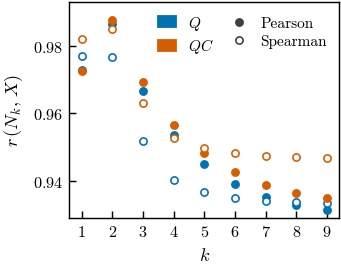

extended_eci_with_imports, 6 digits


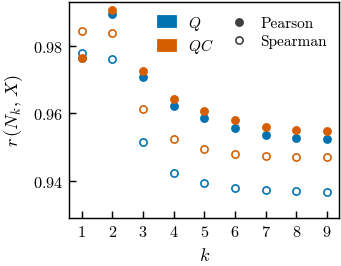

extended_fitness_with_imports, 4 digits


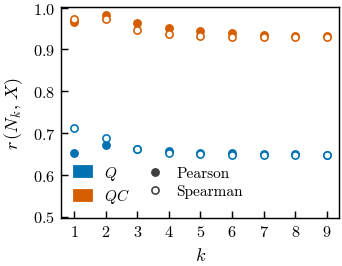

extended_fitness_with_imports, 6 digits


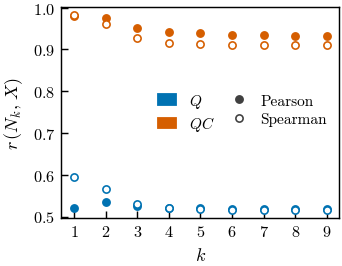

In [3]:
QUANTITIES = ["Q", "CQ"]
COLS = [f"{m}_{q}" for q in QUANTITIES for m in ("pearson", "spearman")]

for algo in ALGOS:
    tables = {}
    for res in RESOLUTIONS:
        f = DATA_DIR / algo / f"corr_input_Q_{res}_digits.parquet"
        if f.exists():
            tables[res] = pd.read_parquet(f)
        else:
            print(f"[manca] {f.relative_to(ROOT)}")
    ylim = common_ylim(list(tables.values()), COLS)       # stesso asse y per 4 e 6 digits
    for res, df in tables.items():
        print(f"{algo}, {res} digits")
        plot_corr_vs_order(df, QUANTITIES, ylim=ylim,
                           save_path=FIG_DIR / f"{algo}_{res}_digits" if SAVE_FIGS else None)